# EvE — Exploration vs Exploitation

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, math, time, json, random
from pathlib import Path
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
from torch.func import functional_call
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.models as tvm
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

Device: cuda


In [2]:
# Configurations 

SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
ORDER_ID = 0

IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2

# Continual Learner
EPOCHS_PER_TASK  = 30
EPOCHS_FIRST_TASK = 60
LR = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
RETRAIN_EPOCHS = 10 # fine-tuning of task t-1 on its reduced weights after the competition
RETRAIN_LR = 0.003

# EvE: exploitation ratios {TAU, ..., MAX_EXPLOIT} (K values), allocation competition
ALLOC_MODE     = "learned"   # "learned" = EvE | "fixed" / "random" = ablations without the allocation learner
FIXED_RATIO    = 0.3         # used by ALLOC_MODE = "fixed"
K              = 5
MAX_EXPLOIT    = 0.5    # largest share of its weights task t-1 may keep
TAU            = 0.1    # smallest exploitation ratio (also the scale of the sparsity loss)
ALLOC_EPOCHS   = 12     # competition epochs
ALLOC_WARMUP   = 2      # first epochs : continual learner trains under random ratios, policy not updated
ALLOC_SAMPLES  = 4      # strategies sampled per batch; each one's baseline is the mean cost of the others
ALLOC_LR       = 0.02   # SGD (no momentum), allocation learner; the advantage is normalised, so this step size is meaningful
ALLOC_CLIP     = 1.0    # gradient-norm clip, allocation learner
COMP_LR        = 0.005  # SGD, continual learner during the competition
COMP_DATA_FRAC = 0.5    # fraction of task t's training data used in the competition
SPARSE_WEIGHT  = 0.2    # weight of L_sparse; raise it if ratios drift to MAX_EXPLOIT, lower it if they collapse to TAU
ENTROPY_WEIGHT = 0.01   # keeps the policy from becoming deterministic too early

RUN_NAME = "eve" if ALLOC_MODE == "learned" else f"eve_{ALLOC_MODE}"
PRETRAINED = True
GN_GROUPS = 32
CIFAR_STEM = True

DATA_DIR = next(Path("/kaggle/input/datasets/prabhanshu22/dl-dataset").rglob("task_order.json")).parent
PLOT_DIR = Path("/kaggle/working/Plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [3]:
# Data Loading

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

eval_tf = [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
train_tf = [T.RandomCrop(IMAGE_SIZE, padding=4), T.RandomHorizontalFlip()] + eval_tf
if IMAGE_SIZE != 32:
    train_tf, eval_tf = [T.Resize(IMAGE_SIZE)] + train_tf, [T.Resize(IMAGE_SIZE)] + eval_tf
transform_train, transform_eval = T.Compose(train_tf), T.Compose(eval_tf)

with open(DATA_DIR / "task_order.json") as f:
    meta = json.load(f)
ORDER = meta["task_orders"][ORDER_ID]

class TaskDataset(Dataset):
    def __init__(self, path, transform):
        data = np.load(path)
        self.images, self.labels, self.transform = data["images"], data["labels_local"], transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

generator = torch.Generator()
generator.manual_seed(SEED)

def get_task_loaders(task_idx):
    """task_idx is the 0-indexed task ID; returns {'train', 'valid', 'test'} loaders."""
    loaders = {}
    for split in ("train", "valid", "test"):
        ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_train if split == "train" else transform_eval)
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"), num_workers=NUM_WORKERS,
                                    pin_memory=True, worker_init_fn=seed_worker, generator=generator)
    return loaders

loaders = [get_task_loaders(ORDER[p]) for p in range(N_TASKS)]
print(f"Order {ORDER_ID} : {ORDER}")

Order 0 : [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]


In [4]:
# GroupNorm helpers
def groups_for(num_channels, preferred=GN_GROUPS):
    if num_channels % preferred == 0:
        return preferred
    return max(math.gcd(preferred, num_channels), 1)

def bn_to_gn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.GroupNorm(groups_for(child.num_features), child.num_features))
        else:
            bn_to_gn(child)
    return module

def prunable_parameters(model):
    """Backbone conv weights only — GroupNorm affine params, biases and the per-task heads are excluded."""
    gn_modules = {n for n, m in model.named_modules() if isinstance(m, nn.GroupNorm)}
    for name, p in model.named_parameters():
        parent = name.rsplit(".", 1)[0]
        if name.endswith(".weight") and parent not in gn_modules and not name.startswith("head."):
            yield name, p

# Metrics
def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def empty_accuracy_matrix(n_tasks):
    return np.full((n_tasks, n_tasks), np.nan, dtype=float)

def set_accuracy(R, after_task, eval_task, acc):
    R[after_task, eval_task] = acc

def forgetting(R):
    n = R.shape[0]
    per_task = np.array([R[i, i] - R[n - 1, i] for i in range(n - 1)], dtype=float)
    return {"per_task": per_task.tolist(), "average": float(np.nanmean(per_task)) if per_task.size else 0.0}

def final_average_accuracy(R):
    return float(np.nanmean(R[R.shape[0] - 1]))

def capacity_stats(masks):
    total, allocated, per_task = 0, 0, {}
    for m in masks.values():
        m = m.cpu().numpy()
        total += m.size
        allocated += int((m > 0).sum())
        for t in np.unique(m):
            t = int(t)
            if t > 0:
                per_task[t] = per_task.get(t, 0) + int((m == t).sum())
    free = total - allocated
    return {"total_parameters": total,
        "active_parameter_count": allocated,
        "allocated_fraction": allocated / total if total else 0.0,
        "free_fraction": free / total if total else 0.0,
        "per_task_parameters": per_task,}

ratio_values = np.linspace(TAU, MAX_EXPLOIT, K)

## Model definition

ResNet-50 (GroupNorm) backbone + one head per task, the `OwnerMasks` manager (which task owns which conv weight) and the `AllocationLearner`.

In [5]:
def build_backbone(pretrained=PRETRAINED):
    weights = tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = tvm.resnet50(weights=weights)
    model = bn_to_gn(model)
    for m in model.modules():
        if isinstance(m, tvm.resnet.Bottleneck):
            nn.init.zeros_(m.bn3.weight)
    if CIFAR_STEM:
        model.conv1.stride = (1, 1)
    feature_dim = model.fc.in_features
    model.fc = nn.Identity()
    model.feature_dim = feature_dim
    return model

class EvEResNet(nn.Module):
    """ResNet-50 (GroupNorm) backbone + a classification head. The head is re-initialised for
    every task and its trained state is stored per task (EvE only isolates the backbone)."""
    def __init__(self, num_classes=CLASSES_PER_TASK):
        super().__init__()
        self.backbone = build_backbone()
        self.head = nn.Linear(self.backbone.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.backbone(x))

class OwnerMasks:
    """Parameter-isolation bookkeeping for EvE.
    owner[name] == t -> conv weight owned by task t (only task t trains it, tasks >= t use it)
    Task 1 owns every weight. At step t the weights owned by task t-1 are split:
    the top e_l fraction (by magnitude) of layer l stays with t-1, the rest becomes task t's.
    Task j always sees the weights owned by tasks <= j. GroupNorm affine is trained in task 1,
    then frozen; every task has its own head, stored here."""
    def __init__(self, model):
        self.model = model
        self.owner = {name: torch.ones_like(p, dtype=torch.uint8) for name, p in prunable_parameters(model)}
        self.heads = {}

    def mask_gradients(self, owner_id):
        """Train only the weights owned by `owner_id`. Weight decay is added here, on those
        weights only, so frozen weights never decay."""
        for name, p in prunable_parameters(self.model):
            if p.grad is not None:
                p.grad.add_(p.data, alpha=WEIGHT_DECAY)
                p.grad.masked_fill_(self.owner[name] != owner_id, 0)

    def rank_fractions(self, owner_id):
        """Per layer: magnitude rank of every weight owned by `owner_id` as a fraction in [0, 1)
        (0 = largest). Weights of other owners get 2.0, so `rank < e` keeps the top-e share."""
        ranks = {}
        for name, p in prunable_parameters(self.model):
            pool = self.owner[name] == owner_id
            r = torch.full(p.shape, 2.0, device=p.device)
            n = int(pool.sum())
            if n > 0:
                order = torch.argsort(p.data.abs()[pool], descending=True)
                pos = torch.empty_like(order)
                pos[order] = torch.arange(n, device=order.device)
                r[pool] = pos.float() / n
            ranks[name] = r
        return ranks

    def allocate(self, prev_task, E):
        """Split task `prev_task`'s weights: per layer the top E[l] fraction stays, the rest goes to prev_task + 1."""
        ranks = self.rank_fractions(prev_task)
        for e, (name, _) in zip(E, prunable_parameters(self.model)):
            pool = self.owner[name] == prev_task
            self.owner[name][pool & (ranks[name] >= float(e))] = prev_task + 1

    def hide(self, upto):
        """Zero every weight owned by a task > upto; returns the hidden values."""
        stash = {}
        for name, p in prunable_parameters(self.model):
            gone = self.owner[name] > upto
            stash[name] = p.data[gone].clone()
            p.data[gone] = 0.0
        return stash

    def unhide(self, stash, upto):
        for name, p in prunable_parameters(self.model):
            p.data[self.owner[name] > upto] = stash[name]

    def view(self, task_id):
        """Show the network task `task_id` sees: later tasks' weights hidden, its own head loaded.
        Returns what `unview` needs to put everything back."""
        saved = {"head": deepcopy(self.model.head.state_dict()), "stash": self.hide(task_id), "task": task_id}
        self.model.head.load_state_dict(self.heads[task_id])
        return saved

    def unview(self, saved):
        self.unhide(saved["stash"], saved["task"])
        self.model.head.load_state_dict(saved["head"])

    def freeze_norms(self):
        for m in self.model.modules():
            if isinstance(m, nn.GroupNorm):
                for p in m.parameters():
                    p.requires_grad_(False)

    def new_head(self):
        self.model.head.reset_parameters()

    def save_head(self, task_id):
        self.heads[task_id] = deepcopy(self.model.head.state_dict())

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.gn1 = nn.GroupNorm(8, cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.gn2 = nn.GroupNorm(8, cout)
        self.shortcut = (nn.Identity() if stride == 1 and cin == cout else
                         nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.GroupNorm(8, cout)))

    def forward(self, x):
        out = F.relu(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class AllocationLearner(nn.Module):
    """Small CNN (stem + 3 stages x 2 residual blocks, GroupNorm, global pooling, FC-128) that maps a
    batch of task t-1 images to logits over the K exploitation ratios of each of the L layers.
    Logits are averaged over the batch -> one strategy per batch. The last layer starts at zero
    (uniform policy)."""
    def __init__(self, n_layers, n_ratios, widths=(32, 64, 128)):
        super().__init__()
        self.n_layers, self.n_ratios = n_layers, n_ratios
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.GroupNorm(8, widths[0]), nn.ReLU())
        blocks, cin = [], widths[0]
        for i, w in enumerate(widths):
            blocks += [ResBlock(cin, w, 1 if i == 0 else 2), ResBlock(w, w, 1)]
            cin = w
        self.stages = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, 128)
        self.out = nn.Linear(128, n_layers * n_ratios)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, x):
        h = self.stages(self.stem(x)).mean(dim=(2, 3))
        return self.out(F.relu(self.fc(h))).view(-1, self.n_layers, self.n_ratios)

## Model summary

In [6]:
model = EvEResNet().to(DEVICE)
eve = OwnerMasks(model)
layer_names = [name for name, _ in prunable_parameters(model)]
L = len(layer_names)

n_total = sum(p.numel() for p in model.parameters())
n_prunable = sum(p.numel() for _, p in prunable_parameters(model))
n_alloc = sum(p.numel() for p in AllocationLearner(L, K).parameters())

print(f"Total Parameters      : {n_total:,}")
print(f"Prunable Parameters   : {n_prunable:,}  ({n_prunable / n_total:.1%} of total)")
print(f"Prunable Layers (L)   : {L}")
print(f"Allocation Learner    : {n_alloc:,} parameters")
print(f"Exploitation Ratios   : {np.round(ratio_values, 3).tolist()}  (K = {K})")
print(f"Allocation Mode       : {ALLOC_MODE}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 231MB/s]


Total Parameters      : 23,528,522
Prunable Parameters   : 23,454,912  (99.7% of total)
Prunable Layers (L)   : 53
Allocation Learner    : 746,025 parameters
Exploitation Ratios   : [0.1, 0.2, 0.3, 0.4, 0.5]  (K = 5)
Allocation Mode       : learned


## Training Definition

In [7]:
criterion = nn.CrossEntropyLoss()

def run_epoch(loader, optimizer=None, scaler=None, train=True, owner=1):
    model.train() if train else model.eval()
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                eve.mask_gradients(owner)
                scaler.step(optimizer)
                scaler.update()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(out, y) * bs
        n += bs
    return total_loss / n, total_acc / n

def fit(task_loaders, epochs, lr, owner, select_best):
    """Train the weights owned by `owner` (plus head) for `epochs`. If select_best, the best-validation
    epoch is kept in memory and reloaded at the end."""
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM, weight_decay=0)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {'epoch': [], 'train_loss': [], 'validation_loss': [], 'train_accuracy': [], 'validation_accuracy': [], 'lr': []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None

    hdr = (f"{'Epoch':>6}  {'T-Loss':>8}  {'V-Loss':>8} {'T-Acc':>8}  {'V-Acc':>8}{'LR':>10}     {'Time':>7}")
    print(hdr)
    print('─' * (len(hdr)+2))

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        cur_lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(task_loaders["train"], optimizer, scaler, train=True, owner=owner)
        va_loss, va_acc = run_epoch(task_loaders["valid"], train=False)
        scheduler.step()

        for k, v in zip(history, [epoch, tr_loss, va_loss, tr_acc, va_acc, cur_lr]):
            history[k].append(v)

        saved_flag = ''
        if select_best and va_acc > best_val_acc:
            best_val_acc, best_epoch, best_state = va_acc, epoch, deepcopy(model.state_dict())
            saved_flag = ' ★'
        print(f'{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  '
              f'{tr_acc:>8.4f}  {va_acc:>8.4f}  {cur_lr:>10.2e}  {time.time() - t0:>6.1f}s{saved_flag}')

    print('─' * len(hdr))
    if select_best:
        model.load_state_dict(best_state)
        print(f'best val acc: {best_val_acc:.4f} @ epoch {best_epoch} (reloaded)')
    return history

def endless(loader):
    while True:
        for batch in loader:
            yield batch

@torch.no_grad()
def final_strategy(allocator, loader):
    """Mean policy over task t-1's validation images -> per-layer argmax ratio and policy statistics."""
    P, n_batches = 0, 0
    for x, _ in loader:
        P = P + allocator(x.to(DEVICE)).mean(0).softmax(-1)
        n_batches += 1
    P = (P / n_batches).cpu().numpy()
    entropy = float((-(P * np.log(P + 1e-12)).sum(-1)).mean() / math.log(K))
    return ratio_values[P.argmax(-1)], {"max_prob": float(P.max(-1).mean()), "entropy": entropy}

def compete(task_id):
    """Task task_id-1 (exploitation) and task_id (exploration) compete for task_id-1's weights.
    Returns the chosen exploitation ratio of every layer (array of length L) and policy statistics."""
    prev = task_id - 1
    learned = ALLOC_MODE == "learned"
    weights = dict(prunable_parameters(model))
    ranks = eve.rank_fractions(prev)
    pool = {n: eve.owner[n] == prev for n in layer_names}
    frozen = {n: eve.owner[n] < prev for n in layer_names}
    head_prev = {f"head.{k}": v for k, v in eve.heads[prev].items()}

    prev_loaders = loaders[prev - 1]
    cur_data = loaders[task_id - 1]["train"].dataset
    half = np.random.RandomState(SEED + task_id).permutation(len(cur_data))[: int(COMP_DATA_FRAC * len(cur_data))]
    cur_batches = endless(DataLoader(Subset(cur_data, half), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                                     pin_memory=True, worker_init_fn=seed_worker, generator=generator))
    ratios = torch.tensor(ratio_values, dtype=torch.float32, device=DEVICE)
    adv_scale = None
    
    if learned:
        allocator = AllocationLearner(L, K).to(DEVICE)
        opt_a = torch.optim.SGD(allocator.parameters(), lr=ALLOC_LR)
    opt_c = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=COMP_LR, momentum=MOMENTUM, weight_decay=0)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt_c, T_max=ALLOC_EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    def forward_pair(e_list, x_p, y_p, x_c, y_c, grad):
        with torch.set_grad_enabled(grad):
            w_prev, w_cur = {}, {}
            for l, n in enumerate(layer_names):
                w = weights[n]
                keep = pool[n] & (ranks[n] < e_list[l])
                rest = pool[n] & ~keep
                w_prev[n] = torch.where(keep, w, w.detach() * frozen[n])
                w_cur[n] = torch.where(rest, w, w.detach())
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out_p = functional_call(model, {**w_prev, **head_prev}, (x_p,))
                out_c = functional_call(model, w_cur, (x_c,))
                l_p, l_c = criterion(out_p, y_p), criterion(out_c, y_c)
        return out_p, out_c, l_p, l_c

    hdr = (f"{'Epoch':>6}  {'L(t-1)':>8} {'L(t)':>8}   {'A(t-1)':>8} {'A(t)':>8}   "
           f"{'mean e':>8}  {'H/Hmax':>7}{'LR':>9}    {'Time':>7}")
    print(hdr)
    print('─' * len(hdr))

    model.train()
    for epoch in range(1, ALLOC_EPOCHS + 1):
        t0 = time.time()
        cur_lr = opt_c.param_groups[0]["lr"]
        policy_on = learned and epoch > ALLOC_WARMUP
        s = {"lp": 0.0, "lc": 0.0, "ap": 0.0, "ac": 0.0, "e": 0.0, "h": 0.0, "n": 0, "bp": 0, "bc": 0}
        for x_p, y_p in prev_loaders["train"]:
            x_p, y_p = x_p.to(DEVICE), y_p.to(DEVICE)
            x_c, y_c = (b.to(DEVICE) for b in next(cur_batches))

            # 1) strategies: sampled from the policy, fixed, or random
            if policy_on:
                logits = allocator(x_p).mean(0)
                dist = Categorical(logits=logits)
                idx = dist.sample((ALLOC_SAMPLES,))
                e_sets = ratios[idx].tolist()
                expected_e = (logits.softmax(-1) * ratios).sum(-1)
                mean_e, ent = expected_e.mean().item(), dist.entropy().mean().item() / math.log(K)
            elif ALLOC_MODE == "fixed":
                e_sets, mean_e, ent = [[FIXED_RATIO] * L], FIXED_RATIO, 0.0
            else:
                e_sets = ratios[torch.randint(K, (1, L), device=DEVICE)].tolist()
                mean_e, ent = float(ratio_values.mean()), 1.0

            # 2) continual-learner forward under the first strategy; the others are only scored
            out_p, out_c, l_p, l_c = forward_pair(e_sets[0], x_p, y_p, x_c, y_c, grad=True)
            loss = l_p + l_c
            if policy_on:
                costs = [loss.item()]
                for e_list in e_sets[1:]:
                    _, _, lp_i, lc_i = forward_pair(e_list, x_p, y_p, x_c, y_c, grad=False)
                    costs.append((lp_i + lc_i).item())

            # 3) continual-learner step
            opt_c.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt_c)
            eve.mask_gradients(prev)
            scaler.step(opt_c)
            scaler.update()

            # 4) allocation-learner step: REINFORCE with a leave-one-out baseline, + L_sparse - entropy bonus
            if policy_on:
                costs = torch.tensor(costs, device=DEVICE)
                advantage = costs - (costs.sum() - costs) / (ALLOC_SAMPLES - 1)
                spread = advantage.std().item()
                adv_scale = spread if adv_scale is None else 0.95 * adv_scale + 0.05 * spread
                advantage = advantage / (adv_scale + 1e-8)
                l_sparse = ((expected_e / TAU) ** 2).mean()
                loss_a = ((advantage * dist.log_prob(idx).sum(-1)).mean() + SPARSE_WEIGHT * l_sparse - ENTROPY_WEIGHT * dist.entropy().mean())
                opt_a.zero_grad()
                loss_a.backward()
                torch.nn.utils.clip_grad_norm_(allocator.parameters(), ALLOC_CLIP)
                opt_a.step()

            bs_p, bs_c = y_p.size(0), y_c.size(0)
            s["lp"] += l_p.item() * bs_p; s["lc"] += l_c.item() * bs_c
            s["ap"] += accuracy(out_p, y_p) * bs_p; s["ac"] += accuracy(out_c, y_c) * bs_c
            s["e"] += mean_e; s["h"] += ent; s["n"] += 1
            s["bp"] += bs_p; s["bc"] += bs_c
        sched.step()
        flag = " warm-up" if learned and not policy_on else ""
        print(f"{epoch:>6}  {s['lp'] / s['bp']:>8.4f}  {s['lc'] / s['bc']:>8.4f}  "
              f"{s['ap'] / s['bp']:>8.4f}  {s['ac'] / s['bc']:>8.4f}  {s['e'] / s['n']:>8.3f}  "
              f"{s['h'] / s['n']:>7.3f}  {cur_lr:>10.2e}  {time.time() - t0:>6.1f}s{flag}")

    print('─' * len(hdr))
    if learned:
        return final_strategy(allocator, prev_loaders["valid"])
    if ALLOC_MODE == "fixed":
        return np.full(L, FIXED_RATIO), {}
    return np.random.RandomState(SEED + task_id).choice(ratio_values, L), {}

## Main Training Loop

- **Task 1:** train on all weights.
- **Task t ≥ 2:** (a) competition between `t−1` and `t` → (b) final per-layer ratios `E*` → (c) `allocate`: `t−1` keeps its top-`e_l` weights per layer, the rest becomes task `t`'s → (d) retrain `t−1` on its reduced set (best validation epoch reloaded, then frozen) → (e) train task `t` on its weights (best validation epoch reloaded) → (f) evaluate every task seen so far on its **test** split.

In [8]:
R = empty_accuracy_matrix(N_TASKS)
all_histories = {}
chosen_ratios = {}    # chosen_ratios[t] = per-layer exploitation ratios used when task t's weights were split with task t+1
kept_fraction = {}    # kept_fraction[t] = share of its pool task t kept (parameter-weighted)
policy_info = {}      # policy_info[t] = max-probability / entropy of the final policy (learned mode)

for task_id in range(1, N_TASKS + 1):
    task_loaders = loaders[task_id - 1]
    task_idx = ORDER[task_id - 1]

    print(f"\n==== Task {task_id}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
    eve.new_head()

    if task_id > 1:
        prev = task_id - 1

        print(f"-- (a) Competition [{ALLOC_MODE}]: task {prev} (exploit) vs task {task_id} (explore), {ALLOC_EPOCHS} epochs --")
        E, info = compete(task_id)

        sizes = np.array([int((eve.owner[n] == prev).sum()) for n in layer_names])
        chosen_ratios[prev] = E
        kept_fraction[prev] = float((E * sizes).sum() / sizes.sum())
        counts = {round(float(r), 2): int(c) for r, c in zip(*np.unique(E, return_counts=True))}
        print(f"-- (b) Chosen ratios per value: {counts} | task {prev} keeps {kept_fraction[prev]:.1%} of its weights")
        if info:
            policy_info[prev] = info
            print(f"       Policy: mean max-prob {info['max_prob']:.2f} | entropy {info['entropy']:.2f} of max (1.00 = uniform, 0.00 = deterministic)")
        eve.allocate(prev, E)                                              # (c)

        print(f"-- (d) Retraining task {prev} on its reduced weights ({RETRAIN_EPOCHS} epochs) --")
        saved = eve.view(prev)                                             # hide task t's weights, load head t-1
        fit(loaders[prev - 1], RETRAIN_EPOCHS, RETRAIN_LR, owner=prev, select_best=True)
        eve.save_head(prev)
        eve.unview(saved)                                                  # task t's weights and head come back

        print(f"-- (e) Training task {task_id} on its weights --")

    n_epochs = EPOCHS_FIRST_TASK if task_id == 1 else EPOCHS_PER_TASK
    all_histories[task_id] = fit(task_loaders, n_epochs, LR, owner=task_id, select_best=True)
    eve.save_head(task_id)
    if task_id == 1:
        eve.freeze_norms()

    # (f) test accuracy of every task learned so far, each with its own weights and head
    for j in range(1, task_id + 1):
        saved = eve.view(j)
        _, acc_j = run_epoch(loaders[j - 1]["test"], train=False)
        eve.unview(saved)
        set_accuracy(R, task_id - 1, j - 1, acc_j)
    print(f"Task {task_id} done | test acc on tasks 1..{task_id}: {np.round(R[task_id - 1, :task_id], 4).tolist()}")


==== Task 1/10  (task-4, classes [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]) ====
 Epoch    T-Loss    V-Loss    T-Acc     V-Acc        LR        Time
─────────────────────────────────────────────────────────────────────
     1    2.1736    2.0193    0.2107    0.3000    1.00e-02     6.1s ★
     2    1.8322    1.9282    0.3520    0.3440    9.99e-03     3.5s ★
     3    1.7059    1.8856    0.3884    0.3320    9.97e-03     3.5s
     4    1.6095    1.6188    0.4351    0.4100    9.94e-03     3.6s ★
     5    1.5149    1.8426    0.4702    0.3600    9.89e-03     3.6s
     6    1.4848    1.6490    0.4707    0.4240    9.83e-03     3.6s ★
     7    1.3635    1.4844    0.5149    0.4780    9.76e-03     3.6s ★
     8    1.4098    1.6700    0.5022    0.4380    9.67e-03     3.6s
     9    1.3173    1.4117    0.5331    0.4980    9.57e-03     3.6s ★
    10    1.2844    1.4400    0.5371    0.5020    9.46e-03     3.6s ★
    11    1.2344    1.3577    0.5584    0.5460    9.33e-03     3.6s ★
    12    1.2227    

In [9]:
# Evaluation Summary

final_acc = final_average_accuracy(R)
forget = forgetting(R)
cap = capacity_stats(eve.owner)
per_task_alloc = [cap["per_task_parameters"].get(t, 0) / cap["total_parameters"] for t in range(1, N_TASKS + 1)]

print(f"final average accuracy across all {N_TASKS} tasks : {final_acc:.4f}")
print(f"average forgetting                                : {forget['average']:.4f}")
print(f"per-task forgetting                                : {[round(v, 4) for v in forget['per_task']]}")
print(f"\nowned parameters per task (of {cap['total_parameters']:,} prunable weights):")
for t in range(1, N_TASKS + 1):
    line = f"  task {t:>2}: {cap['per_task_parameters'].get(t, 0):>11,}  ({per_task_alloc[t - 1]:>6.2%})"
    if t in chosen_ratios:
        line += f"  | mean ratio {chosen_ratios[t].mean():.2f} (min {chosen_ratios[t].min():.1f}, max {chosen_ratios[t].max():.1f}), kept {kept_fraction[t]:.1%} of its pool"
    print(line)
if policy_info:
    print(f"\nfinal policy entropy per step (1.00 = uniform, 0.00 = deterministic): "
          f"{[round(policy_info[t]['entropy'], 2) for t in sorted(policy_info)]}")

final average accuracy across all 10 tasks : 0.7731
average forgetting                                : 0.0009
per-task forgetting                                : [0.011, 0.001, -0.005, 0.006, -0.006, -0.002, 0.007, -0.006, 0.002]

owned parameters per task (of 23,454,912 prunable weights):
  task  1:   4,778,206  (20.37%)  | mean ratio 0.20 (min 0.1, max 0.5), kept 20.4% of its pool
  task  2:   3,437,088  (14.65%)  | mean ratio 0.22 (min 0.1, max 0.5), kept 18.4% of its pool
  task  3:   2,907,927  (12.40%)  | mean ratio 0.22 (min 0.1, max 0.5), kept 19.1% of its pool
  task  4:   2,576,579  (10.99%)  | mean ratio 0.22 (min 0.1, max 0.5), kept 20.9% of its pool
  task  5:   1,901,044  ( 8.11%)  | mean ratio 0.23 (min 0.1, max 0.5), kept 19.5% of its pool
  task  6:   1,445,349  ( 6.16%)  | mean ratio 0.25 (min 0.1, max 0.5), kept 18.4% of its pool
  task  7:   1,401,672  ( 5.98%)  | mean ratio 0.25 (min 0.1, max 0.5), kept 21.9% of its pool
  task  8:     784,774  ( 3.35%)  | mean r

## Plots

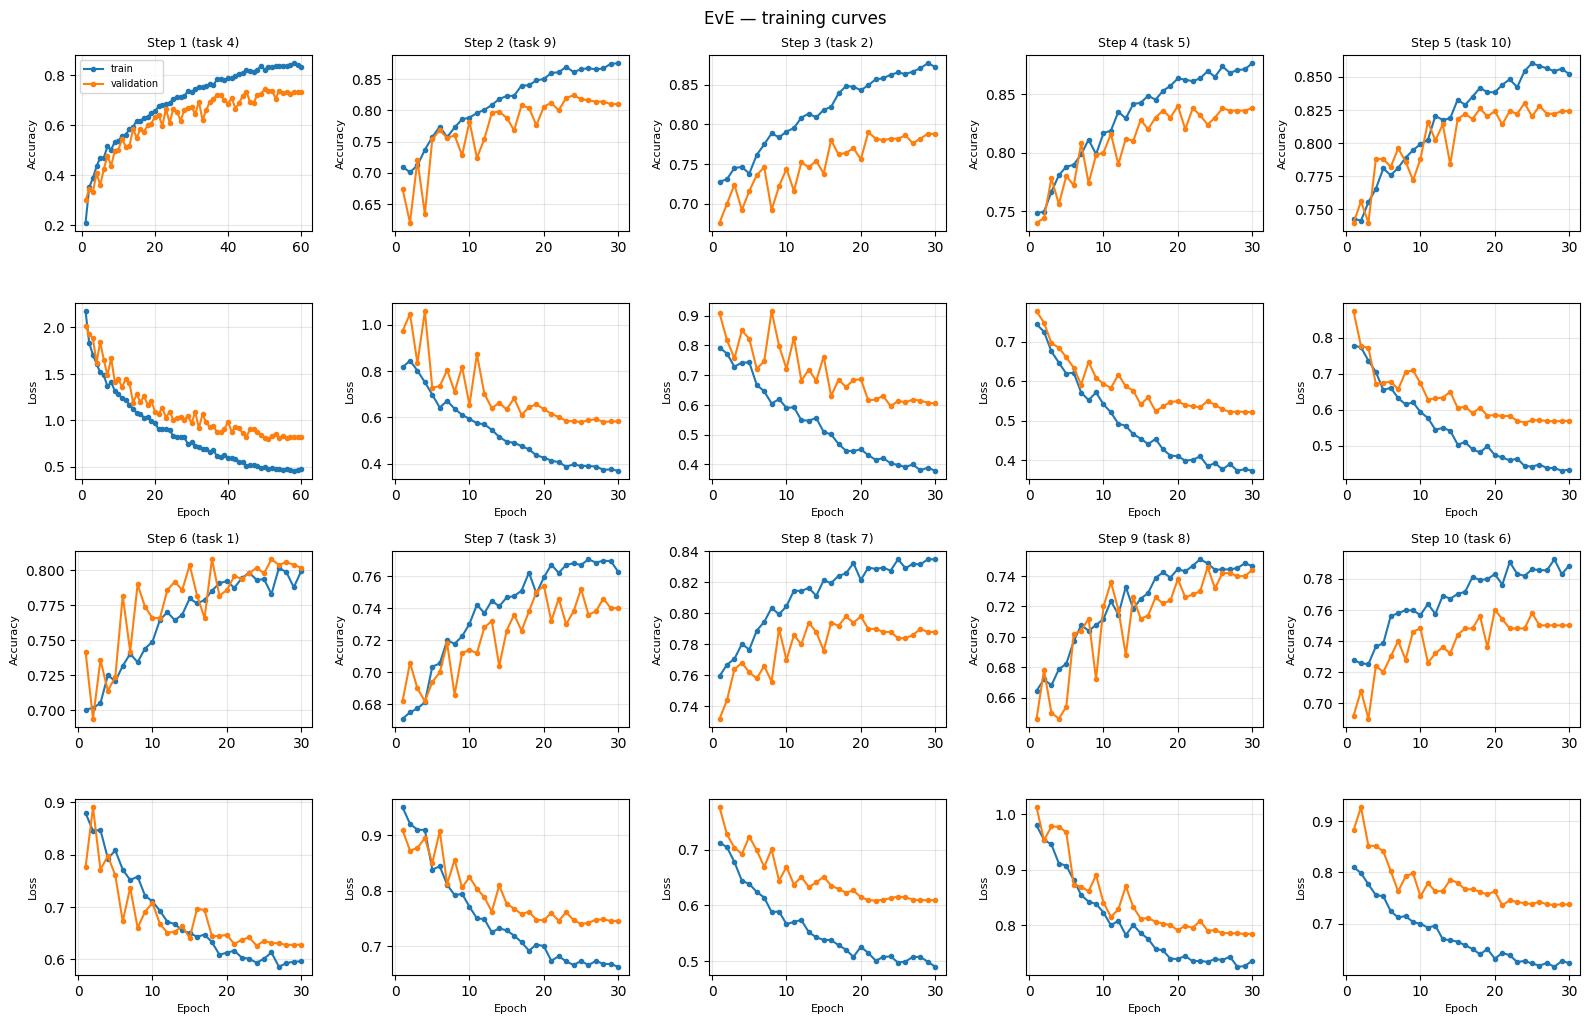

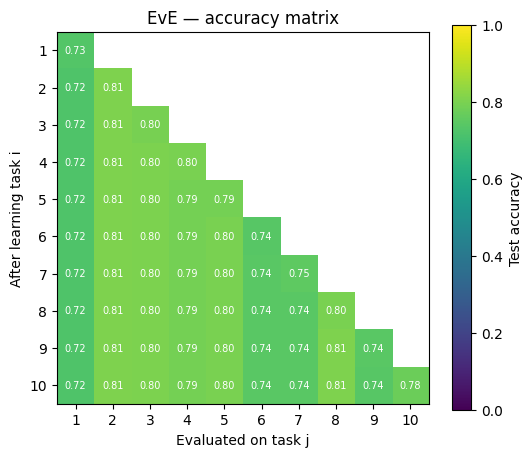

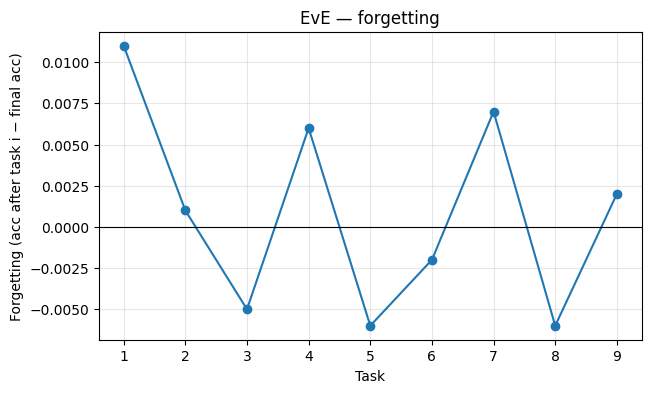

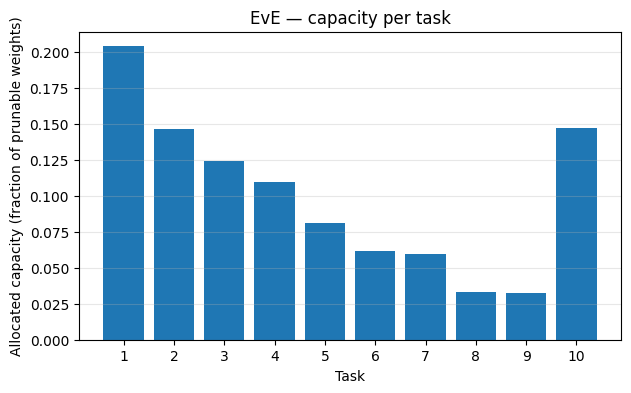

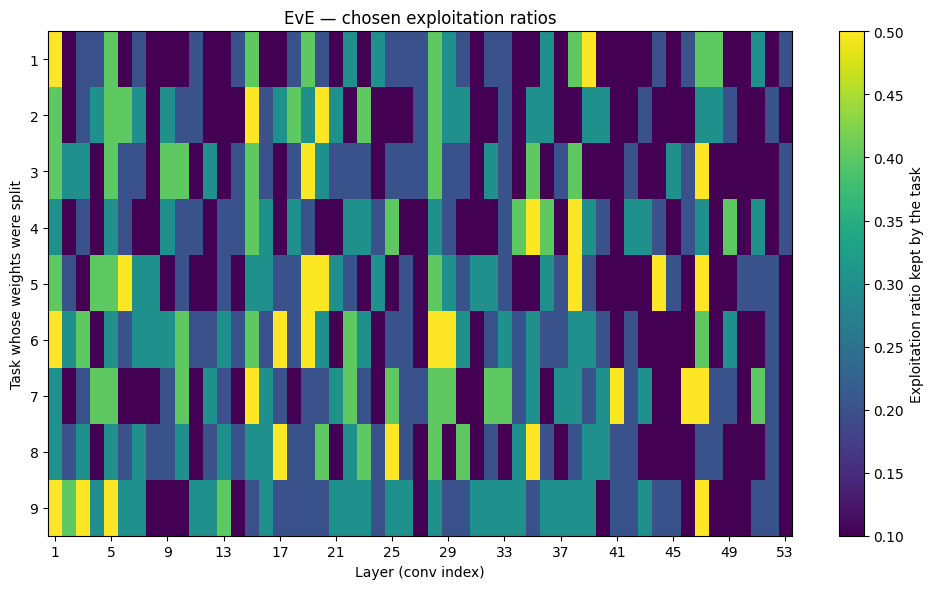

In [10]:
def plot_training_curves(histories, save_path):
    n_cols = 5
    n_blocks = math.ceil(len(histories) / n_cols)
    fig, axes = plt.subplots(2 * n_blocks, n_cols, figsize=(3.2 * n_cols, 2.6 * 2 * n_blocks), squeeze=False)
    for t, h in histories.items():
        r, c = divmod(t - 1, n_cols)
        for row, metric in ((2 * r, "accuracy"), (2 * r + 1, "loss")):
            ax = axes[row, c]
            ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
            ax.plot(h["epoch"], h[f"validation_{metric}"], marker="o", ms=3, label="validation")
            ax.set_ylabel(metric.capitalize(), fontsize=8); ax.grid(alpha=0.3)
            if row == 2 * r:
                ax.set_title(f"Step {t} (task {ORDER[t - 1] + 1})", fontsize=9)
            else:
                ax.set_xlabel("Epoch", fontsize=8)
    axes[0, 0].legend(fontsize=7)
    for ax in axes.flat:
        if not ax.has_data():
            ax.axis("off")
    fig.suptitle("EvE — training curves")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_accuracy_matrix(R, save_path):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(R, vmin=0, vmax=1, cmap="viridis")
    ax.set_xlabel("Evaluated on task j"); ax.set_ylabel("After learning task i")
    ax.set_xticks(range(R.shape[1])); ax.set_yticks(range(R.shape[0]))
    ax.set_xticklabels(range(1, R.shape[1] + 1)); ax.set_yticklabels(range(1, R.shape[0] + 1))
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            if not np.isnan(R[i, j]):
                ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
    fig.colorbar(im, ax=ax, label="Test accuracy"); ax.set_title("EvE — accuracy matrix")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_forgetting(per_task, save_path):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(per_task) + 1), per_task, marker="o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Task"); ax.set_ylabel("Forgetting (acc after task i − final acc)")
    ax.set_title("EvE — forgetting"); ax.grid(alpha=0.3)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_capacity(per_task_alloc, save_path):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(range(1, len(per_task_alloc) + 1), per_task_alloc)
    ax.set_xticks(range(1, len(per_task_alloc) + 1))
    ax.set_xlabel("Task"); ax.set_ylabel("Allocated capacity (fraction of prunable weights)")
    ax.set_title("EvE — capacity per task"); ax.grid(alpha=0.3, axis="y")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_exploitation_ratios(chosen, save_path):
    tasks = sorted(chosen)
    M = np.array([chosen[t] for t in tasks])
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(tasks) + 2.5))
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=ratio_values.min(), vmax=ratio_values.max())
    ax.set_xlabel("Layer (conv index)"); ax.set_ylabel("Task whose weights were split")
    ax.set_yticks(range(len(tasks))); ax.set_yticklabels(tasks)
    ax.set_xticks(range(0, M.shape[1], 4)); ax.set_xticklabels(range(1, M.shape[1] + 1, 4))
    fig.colorbar(im, ax=ax, label="Exploitation ratio kept by the task")
    ax.set_title("EvE — chosen exploitation ratios")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_training_curves(all_histories, PLOT_DIR / f"{RUN_NAME}_training_curves.png")
plot_accuracy_matrix(R, PLOT_DIR / f"{RUN_NAME}_accuracy_matrix.png")
plot_forgetting(forget["per_task"], PLOT_DIR / f"{RUN_NAME}_forgetting.png")
plot_capacity(per_task_alloc, PLOT_DIR / f"{RUN_NAME}_capacity.png")
plot_exploitation_ratios(chosen_ratios, PLOT_DIR / f"{RUN_NAME}_exploitation_ratios.png")